In [1]:
# Project path setup: works whether Jupyter was launched from the project root or notebooks/.
from pathlib import Path
import os
cwd = Path.cwd()
if (cwd / "data").is_dir() and (cwd / "notebooks").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    raise RuntimeError("Open this notebook from the project root or its notebooks/ folder.")
os.chdir(PROJECT_ROOT / "notebooks")
print("Project root:", PROJECT_ROOT)
print("Notebook working directory:", Path.cwd())

Project root: /home/akshat/Desktop/main files (i think)/ml course work/ml project
Notebook working directory: /home/akshat/Desktop/main files (i think)/ml course work/ml project/notebooks


# 07 — Error Analysis of the Final Logistic Regression Model

## Objective

Generate out-of-fold (OOF) predictions for the final Logistic Regression pipeline using stratified five-fold cross-validation on the training dataset. Each review is predicted by a fold model that was not fitted on that review.

The final pipeline uses TF-IDF unigrams and bigrams with `min_df=10`, `max_df=1.0`, `sublinear_tf=True`, and Logistic Regression with L2 regularisation (`C=3`, `solver="liblinear"`). The shared configuration is imported from `src/train.py` so the notebook and scripts do not silently diverge.

We examine class-wise metrics, misclassified reviews, and error patterns across product categories and ratings. The held-out test set is not used for this error analysis.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import StratifiedKFold, cross_val_predict, learning_curve
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    f1_score, balanced_accuracy_score
)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from train import build_pipeline, CV_MACRO_F1

In [3]:
train_df = pd.read_csv("../data/processed/train.csv")

X_train = train_df["text"].astype(str)
y_train = train_df["target"].astype(int)

print("Training samples:", len(X_train))
print("Label distribution:")
print(y_train.value_counts())

Training samples: 32328
Label distribution:
target
0    16172
1    16156
Name: count, dtype: int64


In [4]:
# Build the final Logistic Regression pipeline from the shared source configuration.
# Fit once for in-sample diagnostics; OOF predictions below use fresh fold-specific fits.
best_pipeline = build_pipeline()
best_pipeline.fit(X_train, y_train)
model = best_pipeline

print("Final selected model: Logistic Regression (L2 / Ridge)")
print(f"Recorded CV Macro F1: {CV_MACRO_F1:.4%}")
print("Pipeline:", best_pipeline)

Final selected model: Logistic Regression (L2 / Ridge)
Recorded CV Macro F1: 93.9769%
Pipeline: Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=100000, min_df=10,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=3.0, max_iter=5000, random_state=42,
                                    solver='liblinear'))])


In [5]:
# Coefficient-based feature inspection is available for linear models.
classifier = best_pipeline.named_steps["classifier"]

if hasattr(classifier, "coef_"):
    vectorizer = best_pipeline.named_steps.get("tfidf")

    if vectorizer is None:
        print("No direct TF-IDF step found; inspect this pipeline's feature transformer.")
    else:
        feature_names = vectorizer.get_feature_names_out()
        weights = classifier.coef_[0]

        weights_df = pd.DataFrame({
            "N-gram": feature_names,
            "Weight": weights
        })

        top_ai_words = weights_df.sort_values(
            "Weight", ascending=False
        ).head(50)
        top_human_words = weights_df.sort_values(
            "Weight", ascending=True
        ).head(50)

        print("TOP 50 TOKENS ASSOCIATED WITH CG PREDICTIONS:")
        display(top_ai_words)
        print("TOP 50 TOKENS ASSOCIATED WITH OR PREDICTIONS:")
        display(top_human_words)
else:
    print(
        "The selected model is tree-based and does not expose a single "
        "linear coefficient per token. Use permutation importance or "
        "tree-specific feature importance instead."
    )


TOP 50 TOKENS ASSOCIATED WITH CG PREDICTIONS:


,N-gram,Weight
22171,the only,9.964940
26371,will keep,9.275776
1264,and it,8.284131
1488,and the,7.467013
21309,that it,6.156478
3747,but it,6.096170
9222,had to,5.615925
9461,has the,5.420839
11249,is little,5.359173
25103,very good,5.285131


TOP 50 TOKENS ASSOCIATED WITH OR PREDICTIONS:


,N-gram,Weight
2189,at,-7.194981
6789,even,-6.177310
3690,but,-6.007121
14825,no,-5.480189
15648,on,-5.436808
23672,to,-5.417430
23431,though,-5.392721
579,all,-5.369343
10612,in,-5.330177
449,after,-5.162357


In [6]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Predictions on training data using the fitted model
train_predictions = best_pipeline.predict(X_train)

# Out-of-fold predictions using the same selected hyperparameters
oof_predictions = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict",
    n_jobs=2
)

print("TRAINING PERFORMANCE")
print("--------------------")
print("Accuracy:", accuracy_score(y_train, train_predictions))
print("Macro F1:", f1_score(y_train, train_predictions, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(y_train, train_predictions))

print("\nOUT-OF-FOLD PERFORMANCE")
print("-----------------------")
print("Accuracy:", accuracy_score(y_train, oof_predictions))
print("Macro F1:", f1_score(y_train, oof_predictions, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(y_train, oof_predictions))

print("\nGENERALIZATION GAP")
print("------------------")
print(
    "Macro F1 gap:",
    f1_score(y_train, train_predictions, average="macro")
    - f1_score(y_train, oof_predictions, average="macro")
)


TRAINING PERFORMANCE
--------------------
Accuracy: 0.9801101212571146
Macro F1: 0.9801096155946578
Balanced Accuracy: 0.9801078658812419

OUT-OF-FOLD PERFORMANCE
-----------------------
Accuracy: 0.9397735708982925
Macro F1: 0.9397696450025448
Balanced Accuracy: 0.9397698053060082

GENERALIZATION GAP
------------------
Macro F1 gap: 0.04033997059211303


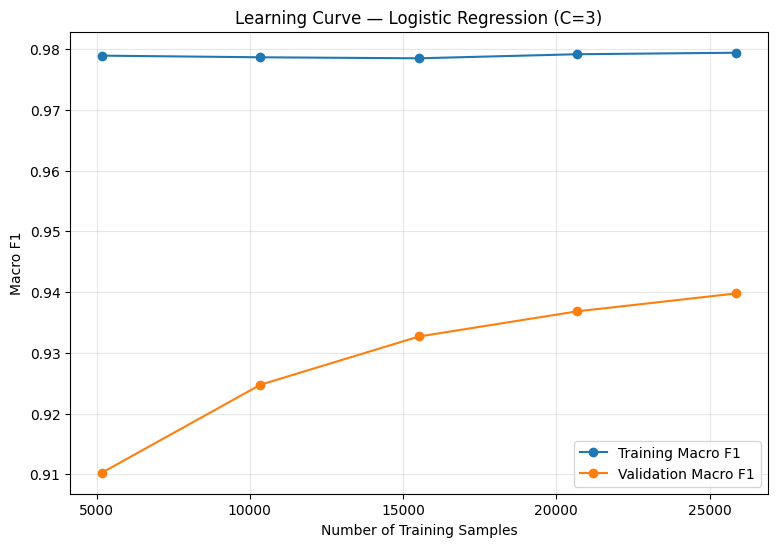

In [7]:
train_sizes, train_scores, validation_scores = learning_curve(
    best_pipeline, X_train, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=2,
    shuffle=True, random_state=42
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, marker="o", label="Training Macro F1")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation Macro F1")
plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1")
plt.title("Learning Curve — Logistic Regression (C=3)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [8]:
error_df = pd.DataFrame({
    "text": X_train.values,
    "actual": y_train.values,
    "predicted": oof_predictions
})

error_df["correct"] = (
    error_df["actual"] == error_df["predicted"]
)

total_errors = (~error_df["correct"]).sum()
error_rate = total_errors / len(error_df)

print("Total reviews:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", total_errors)
print(f"Error rate: {error_rate:.4%}")
print(f"Accuracy: {1 - error_rate:.4%}")

Total reviews: 32328
Correct predictions: 30381
Incorrect predictions: 1947
Error rate: 6.0226%
Accuracy: 93.9774%


In [9]:
# Load the original dataset
raw_df = pd.read_csv("../data/raw/fake reviews dataset.csv")

# Apply the same text cleaning and duplicate removal as Notebook 2
raw_df["text_"] = raw_df["text_"].astype("string").str.strip()

raw_df = raw_df.drop_duplicates(
    subset=["text_"],
    keep="first"
).reset_index(drop=True)

# Extract category and rating metadata
metadata_df = raw_df[
    ["text_", "category", "rating"]
].copy()

# Attach metadata to the OOF error-analysis dataframe
error_df = error_df.merge(
    metadata_df,
    left_on="text",
    right_on="text_",
    how="left",
    validate="one_to_one"
)

# Remove the redundant text column from the merge
error_df.drop(columns=["text_"], inplace=True)

# Verify that every training review was matched
missing_categories = error_df["category"].isna().sum()
missing_ratings = error_df["rating"].isna().sum()

print("Missing categories:", missing_categories)
print("Missing ratings:", missing_ratings)

assert missing_categories == 0, "Some reviews have no matched category."
assert missing_ratings == 0, "Some reviews have no matched rating."

print("\nUpdated error analysis dataset:")
display(error_df.head())

Missing categories: 0
Missing ratings: 0

Updated error analysis dataset:


,text,actual,predicted,correct,category,rating
0,I absolutely love this print/design! I love t...,1,1,True,Home_and_Kitchen_5,5.0
1,Something is very wrong here.\n\nI suppose the...,0,0,True,Movies_and_TV_5,5.0
2,All Megabomber stories are written by people ...,1,1,True,Books_5,2.0
3,We use these in our Data Center and found thes...,0,0,True,Tools_and_Home_Improvement_5,5.0
4,"Just a tad large, but the straps are adjustabl...",0,0,True,Clothing_Shoes_and_Jewelry_5,5.0


In [10]:
print("Accuracy:", accuracy_score(y_train, oof_predictions))

print(
    "Macro F1:",
    f1_score(y_train, oof_predictions, average="macro")
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_train, oof_predictions)
)

print("\nClassification Report:\n")

print(classification_report(
    y_train,
    oof_predictions,
    labels=[0, 1],
    target_names=["OR (Authentic)", "CG (Computer Generated)"],
    digits=4
))

Accuracy: 0.9397735708982925
Macro F1: 0.9397696450025448
Balanced Accuracy: 0.9397698053060082

Classification Report:

                         precision    recall  f1-score   support

         OR (Authentic)     0.9332    0.9474    0.9403     16172
CG (Computer Generated)     0.9465    0.9322    0.9393     16156

               accuracy                         0.9398     32328
              macro avg     0.9399    0.9398    0.9398     32328
           weighted avg     0.9399    0.9398    0.9398     32328



In [11]:
# OR incorrectly predicted as CG
or_misclassified_as_cg = error_df[
    (error_df["actual"] == 0) &
    (error_df["predicted"] == 1)
].copy()

# CG incorrectly predicted as OR
cg_misclassified_as_or = error_df[
    (error_df["actual"] == 1) &
    (error_df["predicted"] == 0)
].copy()

# All misclassified reviews
misclassified = error_df[
    ~error_df["correct"]
].copy()

print("OR incorrectly classified as CG:",
      len(or_misclassified_as_cg))

print("CG incorrectly classified as OR:",
      len(cg_misclassified_as_or))

print("Total misclassified reviews:",
      len(misclassified))

OR incorrectly classified as CG: 851
CG incorrectly classified as OR: 1096
Total misclassified reviews: 1947


In [12]:
pd.set_option("display.max_colwidth", None)

print("OR incorrectly classified as CG:")

display(
    or_misclassified_as_cg[
        ["text", "actual", "predicted", "category", "rating"]
    ].head(5)
)

print("\nCG incorrectly classified as OR:")

display(
    cg_misclassified_as_or[
        ["text", "actual", "predicted", "category", "rating"]
    ].head(5)
)

OR incorrectly classified as CG:


,text,actual,predicted,category,rating
53,"The chemistry between Chase and Violet is undeniably refreshing. Chase is a military man with a toddler daughter, and a widower. Chase's daughter has his heart, and then his deceased wife's childhood friend arrives to see the wife, and claims his and baby Ava's heart. Chase is not sure if he can forget the past and embrace the future. Violet is a trust fund heiress, who is loving , kind , compassionate, and very generous. Upon setting her eyes on Chase, she knows Chase and Ava has stolen her heart. Will Chase forget old hurts and embrace the love he has never had with anyone else? The storyline is great, just too short. How will the flyboy and the heiress meet in the middle to embark on a grand adventure to love?",0,1,Kindle_Store_5,5.0
55,"We've had a couple of Chamberlain garage door openers for several years now, and they work just fine. I bought this remote as a replacement for one that was lost. I've had to replace the battery in one of the original remotes. It's a bit difficult to get the case open to replace the battery, but they last for around 5 years which seems pretty reasonable. The only indication that the battery was failing was a reduction in the operating range of the remote. Programming the remote is very simple (directions are provided with the unit), and it's nice to be able to use several remotes with both garage doors. The removable clip is nice, too, allowing you to carry the remote in a pocket with no sharp edges. Just remember: if you put the remote in your motorcycle jacket, zip it up before you go for a ride (see previous comment about a lost unit).",0,1,Tools_and_Home_Improvement_5,5.0
68,Nice leash with comfortable handle. The leash itself is a little more lightweight than I would've liked but my dog is not really a puller so it will be fine.,0,1,Pet_Supplies_5,5.0
81,"I love to make custard in the cold months, and this is a nice matched set that work very well.",0,1,Home_and_Kitchen_5,5.0
102,I hated this film. It was not my favorite Zac Efron movie.,0,1,Movies_and_TV_5,1.0



CG incorrectly classified as OR:


,text,actual,predicted,category,rating
29,I have narrow feet and this shoe is perfect. I will definitely be buying this shoe again.,1,0,Clothing_Shoes_and_Jewelry_5,5.0
33,"Terrible, complete waste of money. Not a whole lot to say.",1,0,Home_and_Kitchen_5,1.0
38,Excellent\nThis review requires that I go back and read the earlier reviews. This review is based,1,0,Books_5,5.0
50,This item is a total waste of money. Not worth it. I would order from another manufacturer.I had a similar model before and used the Tumbler for years. It worked well and,1,0,Home_and_Kitchen_5,1.0
73,DOES NOT KEEP HAIRS ON FOR A LONG TIME I WILLNOT USE BAGS IN THE HAND FOR THE LONGER TIME,1,0,Sports_and_Outdoors_5,2.0


True Negatives (OR correctly classified): 15321
False Positives (OR incorrectly classified as CG): 851
False Negatives (CG incorrectly classified as OR): 1096
True Positives (CG correctly classified): 15060


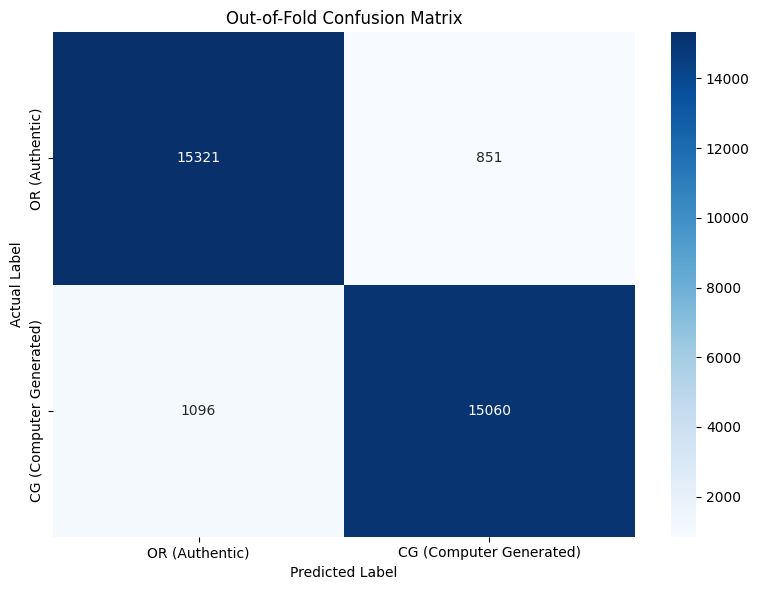

In [13]:
cm = confusion_matrix(
    y_train,
    oof_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives (OR correctly classified):", tn)
print("False Positives (OR incorrectly classified as CG):", fp)
print("False Negatives (CG incorrectly classified as OR):", fn)
print("True Positives (CG correctly classified):", tp)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["OR (Authentic)", "CG (Computer Generated)"],
    yticklabels=["OR (Authentic)", "CG (Computer Generated)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Out-of-Fold Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/oof_confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
category_summary = (
    error_df.groupby("category")
    .agg(
        total_reviews=("correct", "size"),
        incorrect_predictions=(
            "correct",
            lambda x: (~x).sum()
        ),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

category_summary["error_rate"] = (
    1 - category_summary["accuracy"]
)

category_summary = category_summary.sort_values(
    "error_rate",
    ascending=False
)

category_summary

,category,total_reviews,incorrect_predictions,accuracy,error_rate
5,Movies_and_TV_5,2901,231,0.920372,0.079628
0,Books_5,3494,253,0.927590,0.072410
1,Clothing_Shoes_and_Jewelry_5,3025,202,0.933223,0.066777
4,Kindle_Store_5,3736,242,0.935225,0.064775
6,Pet_Supplies_5,3359,195,0.941947,0.058053
9,Toys_and_Games_5,3021,173,0.942734,0.057266
7,Sports_and_Outdoors_5,3164,178,0.943742,0.056258
8,Tools_and_Home_Improvement_5,3147,161,0.948840,0.051160
3,Home_and_Kitchen_5,3261,157,0.951855,0.048145
2,Electronics_5,3220,155,0.951863,0.048137


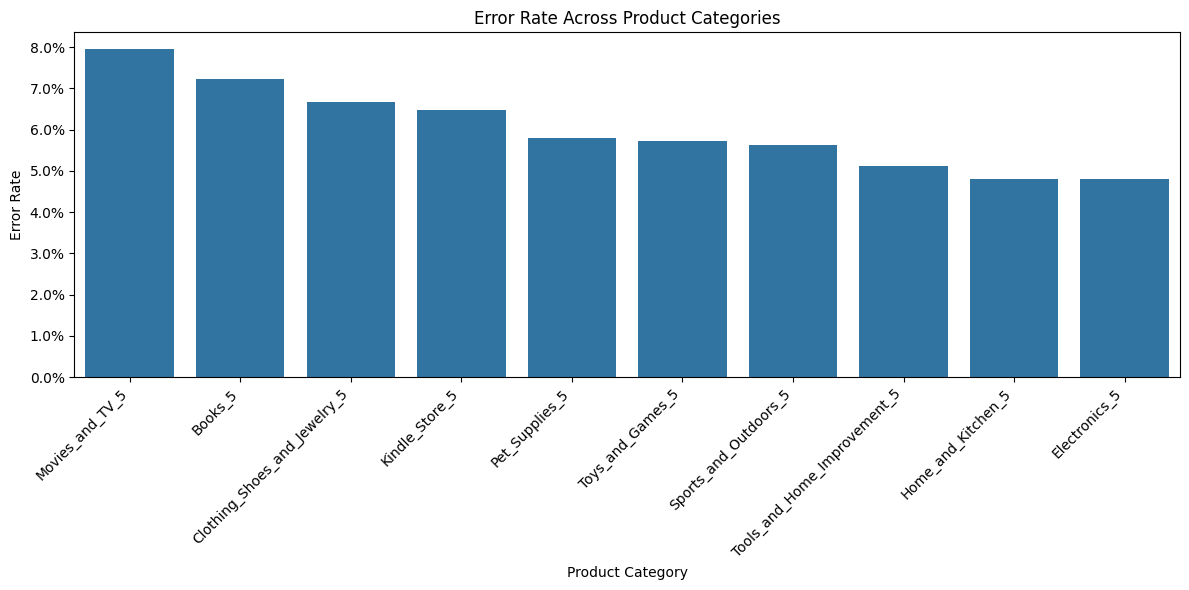

In [15]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=category_summary,
    x="category",
    y="error_rate"
)

ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.title("Error Rate Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Error Rate")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "../results/figures/category_error_rates_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
rating_summary = (
    error_df.groupby("rating")
    .agg(
        total_reviews=("correct", "size"),
        incorrect_predictions=(
            "correct",
            lambda x: (~x).sum()
        ),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

rating_summary["error_rate"] = (
    1 - rating_summary["accuracy"]
)

rating_summary

,rating,total_reviews,incorrect_predictions,accuracy,error_rate
0,1.0,1724,90,0.947796,0.052204
1,2.0,1556,69,0.955656,0.044344
2,3.0,3022,159,0.947386,0.052614
3,4.0,6386,348,0.945506,0.054494
4,5.0,19640,1281,0.934776,0.065224


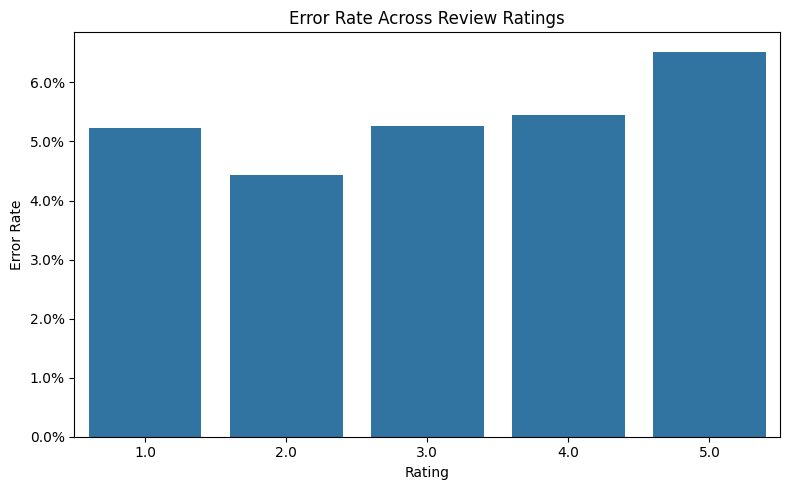

In [17]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=rating_summary,
    x="rating",
    y="error_rate"
)

ax.yaxis.set_major_formatter(PercentFormatter(1))

plt.title("Error Rate Across Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Error Rate")

plt.tight_layout()

plt.savefig(
    "../results/figures/rating_error_rates_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
OUTPUT_PREDICTIONS = Path("../results/final_logistic_regression/predictions")
OUTPUT_PREDICTIONS.mkdir(parents=True, exist_ok=True)
misclassified.to_csv(OUTPUT_PREDICTIONS / "oof_misclassified_reviews.csv", index=False)

print("Misclassified reviews saved successfully.")
print("Number of saved reviews:", len(misclassified))
print("Columns:", misclassified.columns.tolist())

Misclassified reviews saved successfully.
Number of saved reviews: 1947
Columns: ['text', 'actual', 'predicted', 'correct', 'category', 'rating']


## Conclusion

This notebook uses out-of-fold predictions to inspect the final Logistic Regression model on the training data. Each OOF prediction is produced without fitting that fold model on the review being predicted.

Category- and rating-specific error rates are descriptive patterns within this dataset. They do not explain causality or establish why a particular review was misclassified. Linear coefficients indicate model associations, not causal explanations.

The held-out test set is not used in this notebook.